# Калибровка датчика давления с помощью реперных точек

Цель: по известным давлениям фазовых переходов (реперным точкам) в нескольких материалах определить функцию преобразования выходного напряжения 
тензодатчика (мВ) в истинное давление (Па).

Исходные данные: для каждого материала записаны временные ряды сопротивления образца при ступенчатом изменении давления. 
Файлы получены с измерительной установки в формате `.xls`.

## Структура исходных данных:

Каждый файл содержит колонки:

* `Time` - время, показывающее момент получания значения сопротивления

* `OHM` - сопротивление образца, в Ом

* колонка со значением давления, в В (заполнена только первая ячейка для группы значений сопротивления, измеренных при одном давлении)

* колонка, указывающая цикл измерений (заполнена не во всех файлах)

* технические столбцы

Пример данных:

In [25]:
import xlrd
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from scripts.data_processing import inp, fill_press, avg_last, save
import numpy as np
from IPython.display import display, Math

file_name = 'NaCl.xls'

book = xlrd.open_workbook(Path('data/raw') / file_name)
sheet = book.sheet_by_index(0)

data = []
for row in range(sheet.nrows):
    data.append(sheet.row_values(row))


df = pd.DataFrame(data[1:], columns=data[0])

df.head()

,Time,OHM,,,Start Time,46209.71015
0,46209.710162,47058067.2,0.3,1up,Interval,0.000058
1,46209.710509,47735324.8,,,,
2,46209.710567,44720105.6,,,Samples Completed,2185.0
3,46209.710625,45964300.8,,,,
4,46209.710683,42427043.2,,,Last Point on Chart,2185.0


In [2]:
df.iloc[3602:3609]

,Time,OHM,,,Start Time,46209.71015
3602,46210.558796,12754.5312,,,,
3603,46210.558854,12742.2240,,,,
3604,46210.559201,12765.9592,,,,
3605,46210.559259,12871.4856,3.6,2down,,
3606,46210.559317,12878.4904,,,,
3607,46210.559375,12867.2024,,,,
3608,46210.559433,12870.0208,,,,


колонка `Time` читается неправильно, она, а так же техническая информация из 4 и 5 колонок не нужны для дальнейшей обработки.

## Обработка данных

Обработка всех файлов с зависимостями сопротивления от давления производится с помощью цикла, который:

* читает файл в формате .xls
* заполняет пропущенные значения давления
* усредняет последние 25 значений сопротивления
* сохраняет результат в файл excel

In [3]:
materials = {
    'ZnS': 'ZnS.xls',
    'CdS': 'CdS.xls',
    'KBr': 'KBr.xls',
    'NaCl': 'NaCl.xls',
    'Bi2Te3': 'Bi2Te3.xls',
    'dwcnt': 'dwcnt.xls'
}

fill_direction = 'up' #заполнена только первая ячейка для группы значений сопротивления
#fill_direction = 'dn' #заполнена только последняя ячейка для группы значений сопротивления

processed = {}

for name, file_name in materials.items():
    df = inp(file_name) #чтение файла, остаются только необходимые значения
    df = fill_press(df, fill_direction) #обработка пропусков
    df = avg_last(df) #усреднение значений
    processed[name] = df
    save(df, file_name) #сохраняем результат

## Построение графиков

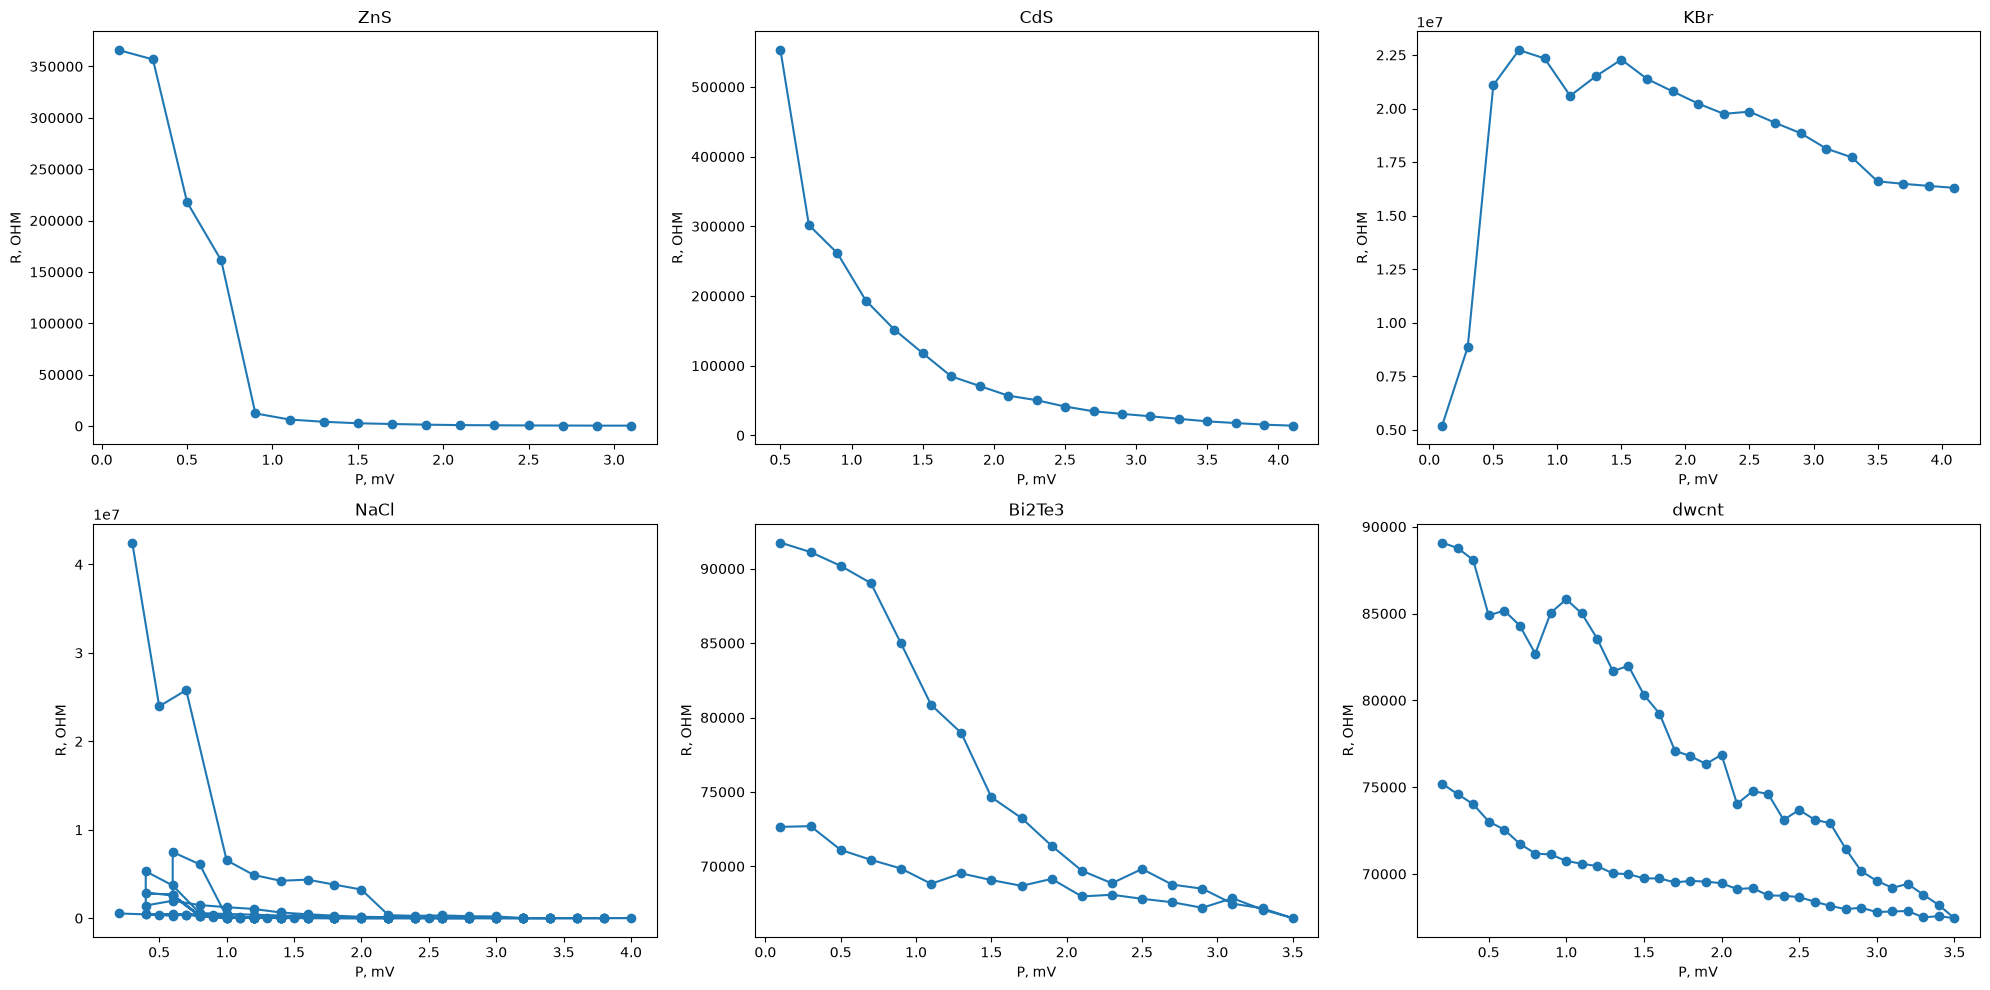

In [4]:
fig, ax= plt.subplots(nrows=2, ncols=3, figsize=(20, 10))

ax = ax.flatten()

i = 0

for m in materials:
    ax[i].plot(processed[m]['P, mV'], processed[m]['R, OHM'], marker='o')
    ax[i].set_xlabel('P, mV')
    ax[i].set_ylabel('R, OHM')
    ax[i].set_title(m)

    i += 1

#graph_file = f"graph_averaged.png" #для сохрания полученных графиков
#plt.savefig(graph_file)

plt.tight_layout()
plt.show()

Данные графики показывают особенности поведения сопротивления с изменением дваления.

Для веществ $ZnS$, $CdS$, $KBr$ измерения проводились только при увеличении давления. Для $Bi_2Te_3$ и нанотрубок (dwcnt) давление сначала увеличивалось, а потом уменьшалось, а для $NaCl$ было измеренно 5 таких циклов.

### Обработка циклов $NaCl$

Построим отдельно графики для каждого цикла $NaCl$.

In [5]:
nacl = processed['NaCl']

nacl['num'] = nacl['series'].str.extract(r'(\d+)').astype(float)
nacl['num'] = nacl['num'].ffill()

nacl.head()

,"P, mV","R, OHM",series,num
0,0.3,4.247040e+07,1up,1.0
1,0.5,2.395705e+07,,1.0
2,0.7,2.579372e+07,,1.0
3,1.0,6.549162e+06,,1.0
4,1.2,4.894861e+06,,1.0


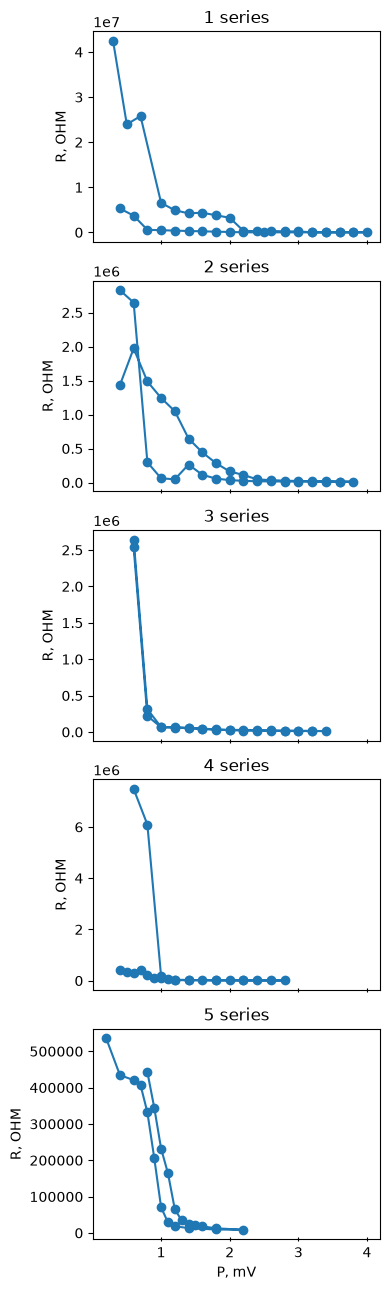

In [6]:
fig, ax = plt.subplots(nrows=5, ncols=1, figsize=(4, 13), sharex=True)

for i, (cycle_num, group) in enumerate(nacl.groupby('num')):
    ax[i].plot(group['P, mV'], group['R, OHM'], marker='o')
    ax[i].set_ylabel('R, OHM')
    ax[i].set_title(f'{i + 1} series')
    ax[i].tick_params(axis='x', direction='inout')

ax[-1].set_xlabel('P, mV')

plt.tight_layout()
plt.show()

Из графиков видно, что переход в циклах происходит примерно при одном и том же давлении.

### Очистка данных от выбросов для $KBr$

На графике $KBr$ можно заметить, что первые две точки являются выбросами (вероятно, они связанны с неплотным прилеганием контакотов прибора
в начале измерения), удалим эти точки, что бы не искажать масштаб.

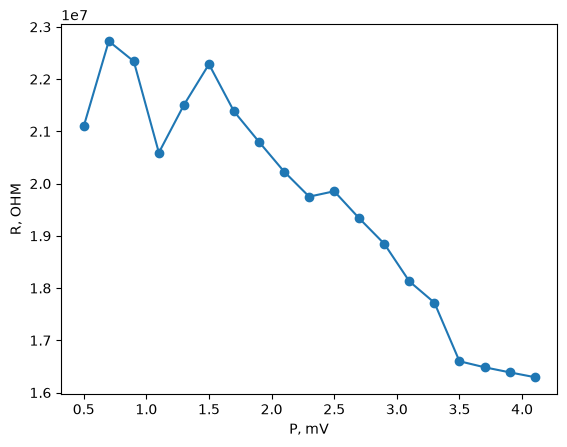

In [7]:
kbr = processed['KBr']

kbr = kbr.iloc[2:].reset_index(drop=True)

fig, ax = plt.subplots()
ax.plot(kbr['P, mV'], kbr['R, OHM'], marker = 'o')
ax.set_xlabel('P, mV')
ax.set_ylabel('R, OHM')

plt.show()

### перестроить некоторые графики в логарифмах, что бы переход был лучше виден? например для хлорида натрия? построить 6 графиков для всех веществ, где отмечены взятые точки фазовых переходов? пересохранить файл для бромида калия без выбросов?

### Построение калибровочных кривых

Из графиков найдем давления, при которых происходят фазовы переход - это область различных особенностей сопртивления. Для $ZnS$, $CdS$, $NaCl$ - это точки резкого падения сопротивления, а для $KBr$, $Bi_2Te_3$ и dwcnt - изменения в наклоне кривых.

Заполним таблицу, которая будет содержать давления, определенные из графиков ($P_{exp}, mV$), и давления, известные из теории ($P, GPa$), для каждоко материала.

In [26]:
points = pd.DataFrame({
    'experimental P exp, mV':[0.7, 2.1, 3.3, 3.0, 2.0, 0.7, 2.1, 2.7], 
    'reference P, GPa':[16.4, 30, 30, 30, 23.0, 14, 18, 24]},
    index = ['ZnS', 'CdS', 'KBr', 'NaCl', 'NaCl', 'Bi2Te3', 'Bi2Te3', 'dwcnt']
)

display(points)

,"experimental P exp, mV","reference P, GPa"
ZnS,0.7,16.4
CdS,2.1,30.0
KBr,3.3,30.0
NaCl,3.0,30.0
NaCl,2.0,23.0
Bi2Te3,0.7,14.0
Bi2Te3,2.1,18.0
dwcnt,2.7,24.0


Найдем коэффиценты зависимости $P(P_{exp})$ методом наименьших квадратов, рассмотрим полиномы 1, 2, 3 степени и логарифмическую функцию.

In [63]:
exp = points['experimental P exp, mV']
ref = points['reference P, GPa']
degrees = [1, 2, 3]
dg_models = {}  #коэффиценты полиномов

for i in degrees:
    dg_models[i] = np.polyfit(exp, ref, i)

exp_log = np.log(exp) 
ln_model = np.polyfit(exp_log, ref, 1) #коэффиценты логарифмической функции

display(Math(fr'\text{{полином  1  степени: }} y_1 = {dg_models[1][0]:.4f}x + {dg_models[1][1]:.4f}'))
display(Math(fr'\text{{полином  2  степени: }} y_2 = {dg_models[2][0]:.4f}x^2 + {dg_models[2][1]:.4f}x + {dg_models[2][2]:.4f}'))
display(Math(fr'\text{{полином  3  степени: }} y_3 = {dg_models[3][0]:.4f}x^3  {dg_models[3][1]:.4f}x^2 + {dg_models[3][2]:.4f}x + {dg_models[3][3]:.4f}'))
display(Math(fr'\text{{логарифмическая функция: }} y_{{ln}} = {ln_model[0]:.4f} \cdot ln(x) + {ln_model[1]:.4f}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Используя найденные коэффицены построим калибровочные кривые.

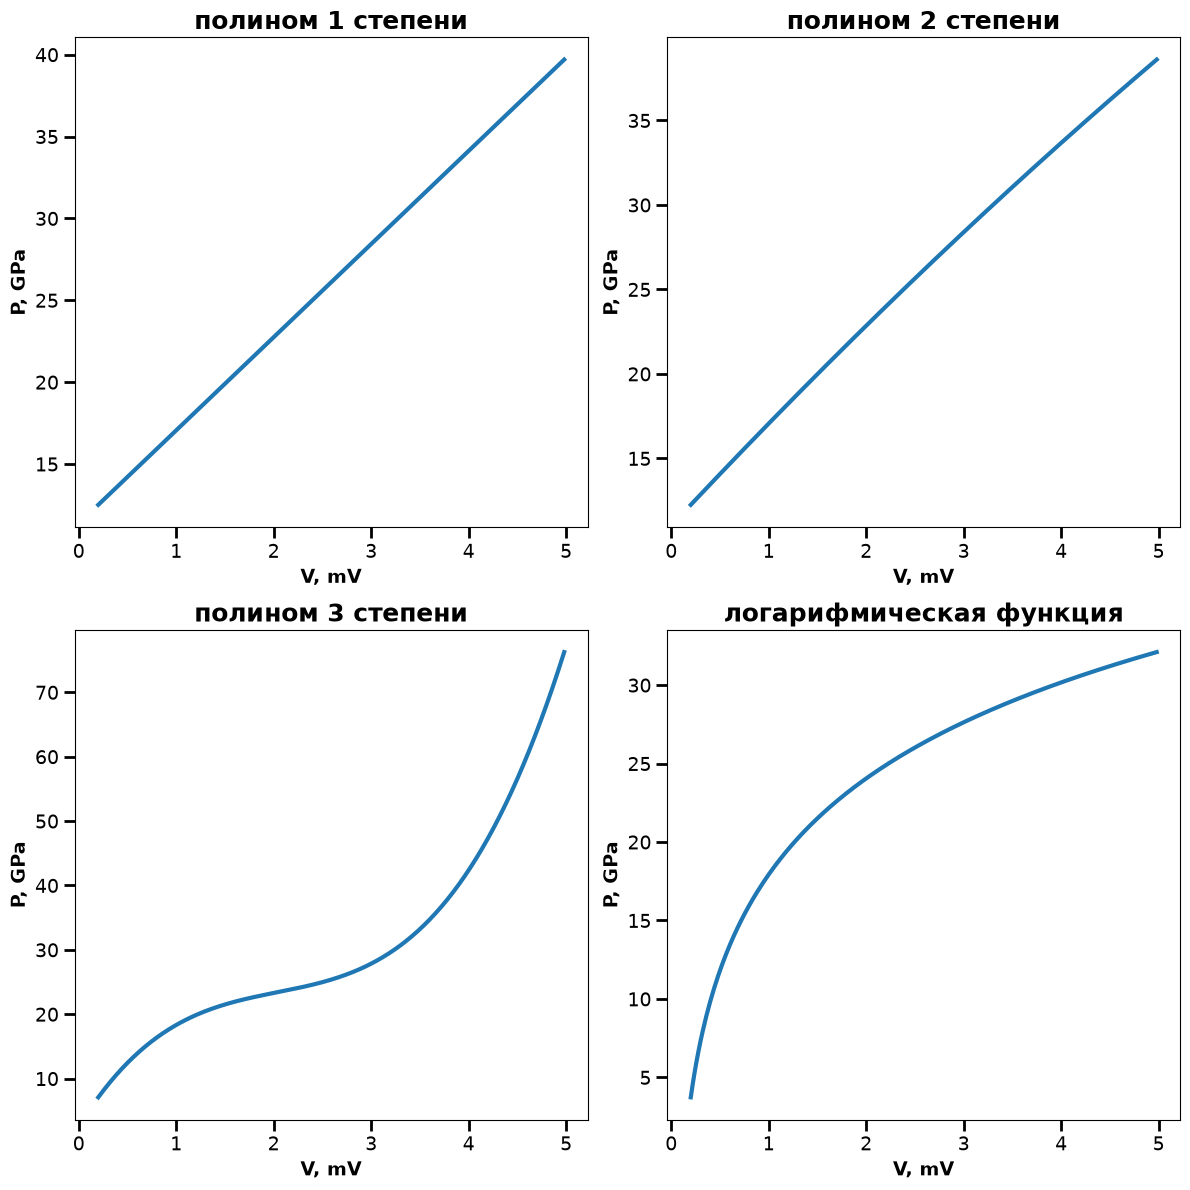

In [64]:
e = np.arange(0.2, 5, 0.02) #V

fig, ax = plt.subplots(nrows = 2, ncols = 2, figsize = (12, 12))

for i in range(2):
    ax[0][i].plot(e, np.polyval(dg_models[i + 1], e), linewidth=3)
    ax[0][i].set_xlabel('V, mV', fontsize=14, fontweight='bold')
    ax[0][i].set_ylabel('P, GPa', fontsize=14, fontweight='bold')
    ax[0][i].set_title(f'полином {i + 1} степени', fontsize=18, fontweight='bold')
    ax[0][i].tick_params(axis='both', which='major', labelsize=14, width=2, length=8)

ax[1][0].plot(e, np.polyval(dg_models[3], e), linewidth=3)
ax[1][0].set_xlabel('V, mV', fontsize=14, fontweight='bold')
ax[1][0].set_ylabel('P, GPa', fontsize=14, fontweight='bold')
ax[1][0].set_title(f'полином {3} степени', fontsize=18, fontweight='bold')
ax[1][0].tick_params(axis='both', which='major', labelsize=14, width=2, length=8)

ax[1][1].plot(e, np.polyval(ln_model, np.log(e)), linewidth=3)
ax[1][1].set_xlabel('V, mV', fontsize=14, fontweight='bold')
ax[1][1].set_ylabel('P, GPa', fontsize=14, fontweight='bold')
ax[1][1].set_title(f'логарифмическая функция', fontsize=18, fontweight='bold')
ax[1][1].tick_params(axis='both', which='major', labelsize=14, width=2, length=8)
      
plt.tight_layout()
plt.show()